<a href="https://colab.research.google.com/github/ReinertYosua/Deep-Isolation-Forest-Autoencoder-LSTM/blob/main/Deep_Isolation_Forest_Autoencoder_%2B_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, RepeatVector, TimeDistributed

# Dataset transaksi keuangan (misal)
data = pd.DataFrame({
    'amount': np.random.normal(100, 10, 1000),
    'category': np.random.randint(1, 5, 1000),
    'timestamp': pd.date_range(start='2024-01-01', periods=1000, freq='T')
})

data_2 = data

# Fitur yang digunakan
features = ['amount', 'category']
X = data[features].values

# Skala data
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Reshape data menjadi (samples, timesteps, features)
timesteps = 10
X_reshaped = np.array([X_scaled[i:i+timesteps] for i in range(len(X_scaled) - timesteps)])
indices = np.array(range(timesteps, len(X_scaled)))  # Simpan indeks yang sesuai

# Bangun LSTM Autoencoder
model = Sequential([
    LSTM(64, activation='relu', input_shape=(timesteps, X.shape[1]), return_sequences=False),
    RepeatVector(timesteps),
    LSTM(64, activation='relu', return_sequences=True),
    TimeDistributed(Dense(X.shape[1]))
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# Latih model
model.fit(X_reshaped, X_reshaped, epochs=10, batch_size=32, validation_split=0.1)

# Prediksi dan hitung error rekonstruksi
X_pred = model.predict(X_reshaped)
mse = np.mean(np.power(X_reshaped - X_pred, 2), axis=(1, 2))

# Threshold untuk menentukan anomali
threshold = np.percentile(mse, 95)
anomalies = mse > threshold

print(f"Jumlah anomali terdeteksi: {np.sum(anomalies)}")


<ipython-input-52-eebd3c9b4e8b>:12: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  'timestamp': pd.date_range(start='2024-01-01', periods=1000, freq='T')
/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                        │ (None, 64)                  │          17,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_4 (RepeatVector)       │ (None, 10, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_9 (LSTM)                        │ (None, 10, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_4 (TimeDistributed) │ (None, 10, 2)               │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 50,306 (196.51 KB)

 Trainable params: 50,306 (196.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.2371 - val_loss: 0.1073
Epoch 2/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1016 - val_loss: 0.0960
Epoch 3/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0891 - val_loss: 0.0881
Epoch 4/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0819 - val_loss: 0.0794
Epoch 5/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0774 - val_loss: 0.0762
Epoch 6/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0727 - val_loss: 0.0727
Epoch 7/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0699 - val_loss: 0.0711
Epoch 8/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0678 - val_loss: 0.0698
Epoch 9/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0664 - val_loss: 0.0695
Epoch 10/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0668 - val_loss: 0.0693
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
Jumlah anomali terdeteksi: 50


In [ ]:
# Menyiapkan DataFrame untuk menyimpan hasil
data['anomaly'] = False  # Inisialisasi kolom anomaly
data['mse'] = np.nan  # Inisialisasi kolom mse

# Menandai data anomali di DataFrame asli menggunakan .loc
for i in range(len(anomalies)):
    if anomalies[i]:
        data.loc[indices[i], 'anomaly'] = True  # Menandai data anomali
        data.loc[indices[i], 'mse'] = mse[i]  # Menyimpan skor MSE

# Menghapus data yang tidak memiliki skor MSE (data awal)
data = data.dropna(subset=['mse'])

# Pisahkan data anomali dan non-anomali
anomalies_df = data[data['anomaly'] == True]
non_anomalies_df = data[data['anomaly'] == False]

# Gabungkan keduanya
combined_df = pd.concat([anomalies_df, non_anomalies_df], ignore_index=True)

# Menampilkan DataFrame gabungan
print(combined_df[['timestamp', 'amount', 'category', 'anomaly', 'mse']])

data

             timestamp      amount  category  anomaly       mse
0  2024-01-01 00:22:00  100.018198         1     True  0.113468
1  2024-01-01 00:23:00   86.778599         1     True  0.106272
2  2024-01-01 00:24:00  102.061671         1     True  0.101663
3  2024-01-01 01:16:00  111.522063         1     True  0.103233
4  2024-01-01 01:17:00   92.302613         4     True  0.110226
5  2024-01-01 01:18:00   78.480680         1     True  0.103256
6  2024-01-01 01:19:00  108.893685         1     True  0.105908
7  2024-01-01 01:23:00   84.123292         3     True  0.113740
8  2024-01-01 01:24:00  110.824813         2     True  0.109886
9  2024-01-01 02:12:00  111.502343         1     True  0.105150
10 2024-01-01 02:13:00   93.678700         3     True  0.113914
11 2024-01-01 03:08:00  103.616110         2     True  0.105436
12 2024-01-01 05:21:00   93.264911         1     True  0.104773
13 2024-01-01 05:24:00   98.029629         4     True  0.115253
14 2024-01-01 05:25:00   96.020400      

,amount,category,timestamp,anomaly,mse
22,100.018198,1,2024-01-01 00:22:00,True,0.113468
23,86.778599,1,2024-01-01 00:23:00,True,0.106272
24,102.061671,1,2024-01-01 00:24:00,True,0.101663
76,111.522063,1,2024-01-01 01:16:00,True,0.103233
77,92.302613,4,2024-01-01 01:17:00,True,0.110226
78,78.480680,1,2024-01-01 01:18:00,True,0.103256
79,108.893685,1,2024-01-01 01:19:00,True,0.105908
83,84.123292,3,2024-01-01 01:23:00,True,0.113740
84,110.824813,2,2024-01-01 01:24:00,True,0.109886
132,111.502343,1,2024-01-01 02:12:00,True,0.105150


In [ ]:
data_2[data_2['anomaly']==True]

,amount,category,timestamp,anomaly,mse
22,100.018198,1,2024-01-01 00:22:00,True,0.113468
23,86.778599,1,2024-01-01 00:23:00,True,0.106272
24,102.061671,1,2024-01-01 00:24:00,True,0.101663
76,111.522063,1,2024-01-01 01:16:00,True,0.103233
77,92.302613,4,2024-01-01 01:17:00,True,0.110226
78,78.480680,1,2024-01-01 01:18:00,True,0.103256
79,108.893685,1,2024-01-01 01:19:00,True,0.105908
83,84.123292,3,2024-01-01 01:23:00,True,0.113740
84,110.824813,2,2024-01-01 01:24:00,True,0.109886
132,111.502343,1,2024-01-01 02:12:00,True,0.105150


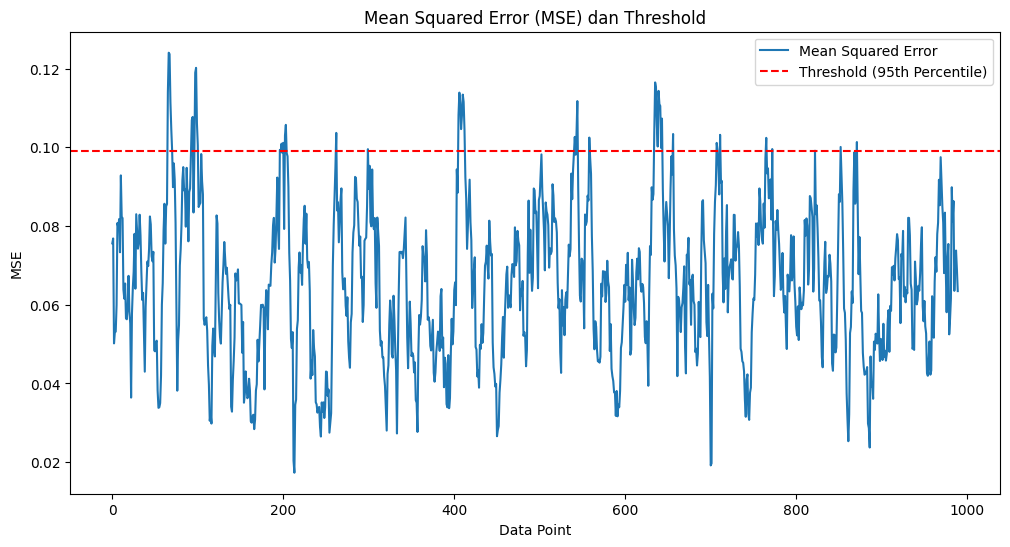

In [ ]:
# Visualisasi MSE dan threshold
plt.figure(figsize=(12, 6))
plt.plot(mse, label='Mean Squared Error')
plt.axhline(y=threshold, color='r', linestyle='--', label='Threshold (95th Percentile)')
plt.title('Mean Squared Error (MSE) dan Threshold')
plt.xlabel('Data Point')
plt.ylabel('MSE')
plt.legend()
plt.show()




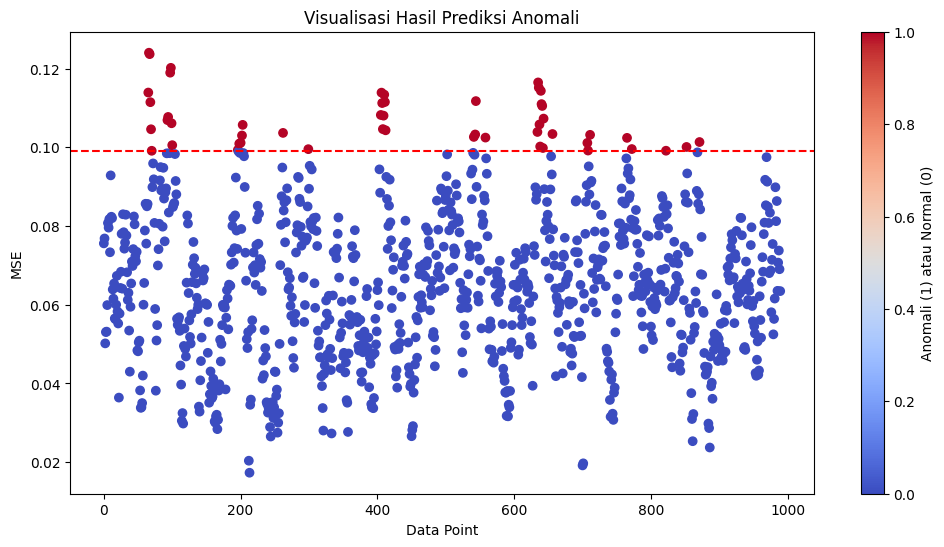

In [ ]:
# Deteksi anomali: Jika MSE lebih besar dari threshold, maka dianggap anomali
# anomalies = mse > threshold

# Plot prediksi anomali
plt.figure(figsize=(12,6))
plt.scatter(range(len(mse)), mse, c=anomalies, cmap='coolwarm', label='Anomali')
plt.axhline(y=threshold, color='r', linestyle='--', label='Threshold')
plt.title('Visualisasi Hasil Prediksi Anomali')
plt.xlabel('Data Point')
plt.ylabel('MSE')
plt.colorbar(label='Anomali (1) atau Normal (0)')
plt.show()


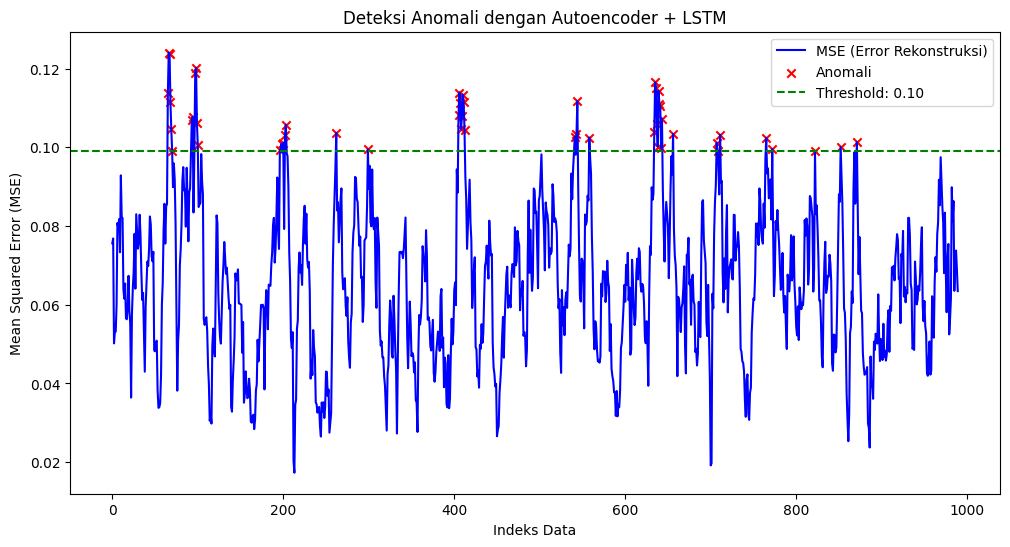

In [ ]:
import matplotlib.pyplot as plt

# Visualisasi Anomali Deep Isolation Forest (Autoencoder + LSTM)

# Indeks data (dari 0 sampai jumlah data)
index = np.arange(len(mse))

# Buat plot untuk rekonstruksi error (MSE)
plt.figure(figsize=(12, 6))
plt.plot(index, mse, label='MSE (Error Rekonstruksi)', color='blue')

# Tandai titik anomali dengan warna merah
plt.scatter(index[anomalies], mse[anomalies], color='red', label='Anomali', marker='x')

# Garis threshold (untuk membedakan antara normal dan anomali)
plt.axhline(y=threshold, color='green', linestyle='--', label=f'Threshold: {threshold:.2f}')

# Tambahkan label dan judul
plt.title('Deteksi Anomali dengan Autoencoder + LSTM')
plt.xlabel('Indeks Data')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()

# Tampilkan plot
plt.show()


<ipython-input-10-1ae1d2c18213>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['anomaly'] = anomalies


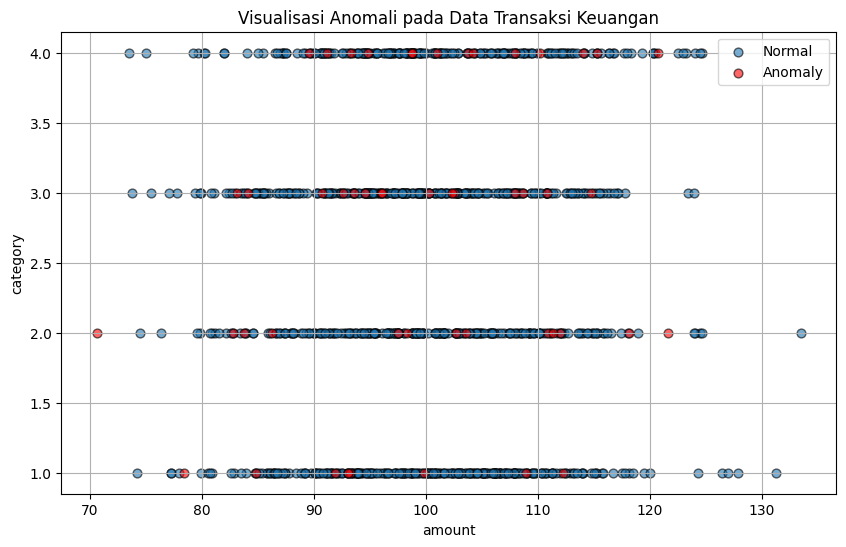

In [ ]:
import matplotlib.pyplot as plt

# Plot hasil prediksi dengan visualisasi anomali
def plot_anomalies(data, anomalies, feature1='amount', feature2='category'):
    # Menambahkan kolom anomali ke dataframe
    data['anomaly'] = anomalies
    normal_data = data[data['anomaly'] == False]
    anomaly_data = data[data['anomaly'] == True]

    # Plot fitur 'amount' vs 'category'
    plt.figure(figsize=(10, 6))

    # Plot data normal
    plt.scatter(normal_data[feature1], normal_data[feature2], label='Normal', alpha=0.6, edgecolor='k', s=40)

    # Plot data anomali
    plt.scatter(anomaly_data[feature1], anomaly_data[feature2], label='Anomaly', color='r', alpha=0.6, edgecolor='k', s=40)

    # Tambahan detail plot
    plt.title('Visualisasi Anomali pada Data Transaksi Keuangan')
    plt.xlabel(feature1)
    plt.ylabel(feature2)
    plt.legend()
    plt.grid(True)
    plt.show()

# Memanggil fungsi visualisasi dengan data asli dan hasil anomali
data_without_timestamp = data.drop(columns=['timestamp'])
plot_anomalies(data_without_timestamp.iloc[timesteps:], anomalies)


<ipython-input-12-8c667d7d43fc>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['anomaly'] = anomalies


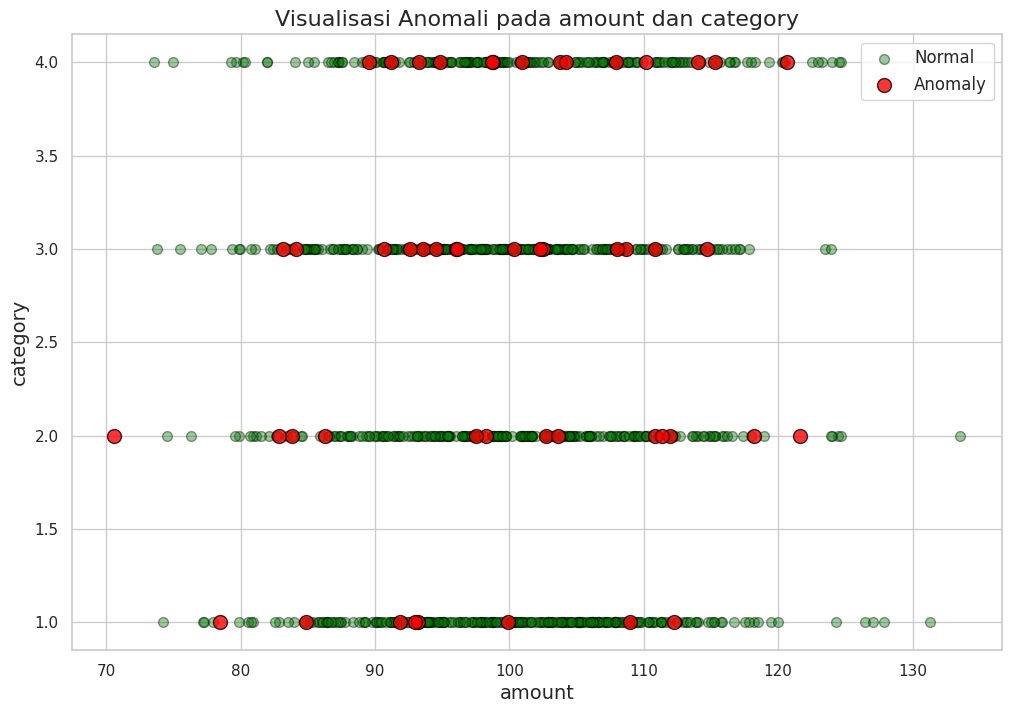

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot hasil prediksi dengan visualisasi anomali
def plot_anomalies_v2(data, anomalies, feature1='amount', feature2='category'):
    # Menambahkan kolom anomali ke dataframe
    data['anomaly'] = anomalies
    normal_data = data[data['anomaly'] == False]
    anomaly_data = data[data['anomaly'] == True]

    # Set gaya plot
    plt.figure(figsize=(12, 8))
    sns.set(style="whitegrid")

    # Plot data normal
    plt.scatter(normal_data[feature1], normal_data[feature2],
                label='Normal', color='green', alpha=0.4, edgecolor='black', s=50)

    # Plot data anomali dengan ukuran lebih besar
    plt.scatter(anomaly_data[feature1], anomaly_data[feature2],
                label='Anomaly', color='red', alpha=0.8, edgecolor='black', s=100)

    # Menambahkan judul dan label
    plt.title(f'Visualisasi Anomali pada {feature1} dan {feature2}', fontsize=16)
    plt.xlabel(feature1, fontsize=14)
    plt.ylabel(feature2, fontsize=14)

    # Menampilkan legenda
    plt.legend(loc='upper right', fontsize=12)

    # Menampilkan grid
    plt.grid(True)

    # Tampilkan plot
    plt.show()

# Memanggil fungsi visualisasi dengan data asli dan hasil anomali
data_without_timestamp = data.drop(columns=['timestamp'])
plot_anomalies_v2(data_without_timestamp.iloc[timesteps:], anomalies)


<ipython-input-11-63b314c31e3b>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['anomaly'] = anomalies


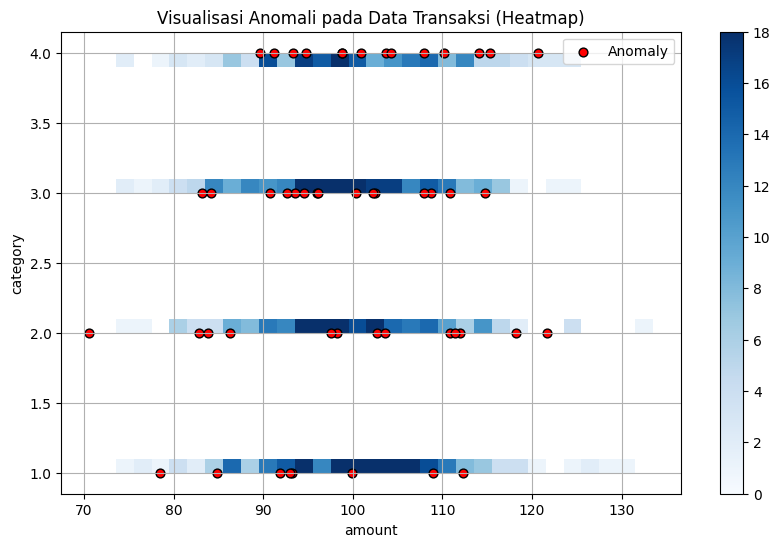

In [ ]:
import seaborn as sns

# Fungsi visualisasi dengan Heatmap dan menandai anomali
def plot_anomalies_heatmap(data, anomalies, feature1='amount', feature2='category'):
    # Menambahkan kolom anomali ke dataframe
    data['anomaly'] = anomalies
    normal_data = data[data['anomaly'] == False]
    anomaly_data = data[data['anomaly'] == True]

    # Buat plot heatmap (2D histogram) untuk data normal
    plt.figure(figsize=(10, 6))

    # Membuat heatmap dengan seaborn
    sns.histplot(normal_data, x=feature1, y=feature2, bins=30, pmax=.8, cmap="Blues", cbar=True)

    # Menandai anomali dengan scatter plot di atas heatmap
    plt.scatter(anomaly_data[feature1], anomaly_data[feature2], label='Anomaly', color='r', edgecolor='k', s=40)

    # Tambahan detail plot
    plt.title('Visualisasi Anomali pada Data Transaksi (Heatmap)')
    plt.xlabel(feature1)
    plt.ylabel(feature2)
    plt.legend()
    plt.grid(True)
    plt.show()

# Memanggil fungsi visualisasi dengan data dan hasil anomali
plot_anomalies_heatmap(data_without_timestamp.iloc[timesteps:], anomalies)
